In [1]:
# Interfaz
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
import numpy as np
import scipy.signal as sig
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF
import Funciones as Funciones
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'svg'

# =========================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'

color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'

line_width = 1.5


fc = FileChooser('Señales AC3E/Femenino')
fc.layout = widgets.Layout(width='auto')
display(fc)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales AC3E\Femenino', filename='', title='', show_…

In [2]:
archivo = Path(fc.selected)
nombre_archivo = archivo.name
datos = np.loadtxt(archivo, delimiter='\t', skiprows=1)
fs_r = 8000
to = 0
tf = 50
tiempos = np.arange(to, tf, 1000/fs_r)


señal_MBK  = datos[:, 0] - np.mean(datos[:, 0])

flujo_ovv  = datos[:, 4]
flujo_ovv= Funciones.Detrend(tiempos,flujo_ovv)
flujo_ovv = flujo_ovv+abs(min(flujo_ovv))
flujo_ovv = flujo_ovv/max(abs(flujo_ovv))



señal_ACC  = -datos[:, 1]
señal_ACC  = señal_ACC - np.mean(señal_ACC)

if max(abs(señal_ACC)) > 0:
    señal_ACC = señal_ACC / max(abs(señal_ACC)) 
#señal_ACC = sig.filtfilt(b,a,señal_ACC)

señal_EGG  = datos[:, 3]
señal_dEGG = np.gradient(señal_EGG)
señal_OVV  = datos[:, 2] - np.mean(datos[:, 2])
if max(abs(señal_OVV)) > 0:
    señal_OVV = señal_OVV / max(abs(señal_OVV)) 
if max(señal_dEGG) > 0:
    señal_dEGG = señal_dEGG / max(señal_dEGG) 


norma = 'frobenius'
# ==============================================================================================================================================================
SP = CONMF.NNMF_GIF(speech=señal_MBK,
                acelerometro=señal_ACC,
                dEGG = señal_dEGG,
                tiempos=tiempos,
                fs=fs_r,
                norma=norma,
                pre_iteraciones=0,
                iteraciones=251,
                p_filtro=12,
                alfa=0.96,
                beta_speech=0.55,
                beta_acc= 0.55,
                pre_enfasis_speech=True,
                pre_enfasis_acc=True,
                duracion=5.5,
                guardar_proceso=True,
                normalizar_espectrogramas=True,
                ventana = 'boxcar'
)


In [3]:

conmf_flujo1_speech = Funciones.Detrend(SP.tiempos_gve,SP.flujo1_speech)
conmf_flujo1_speech = conmf_flujo1_speech+abs(min(conmf_flujo1_speech))
conmf_flujo1_speech = conmf_flujo1_speech/max(abs(conmf_flujo1_speech))

conmf_flujo2_speech = Funciones.Detrend(SP.tiempos_gve,SP.flujo2_speech)
conmf_flujo2_speech = conmf_flujo2_speech+abs(min(conmf_flujo2_speech))
conmf_flujo2_speech = conmf_flujo2_speech/max(abs(conmf_flujo2_speech))



conmf_flujo1_acc = Funciones.Detrend(SP.tiempos_gve,SP.flujo1_acc)
conmf_flujo1_acc = conmf_flujo1_acc+abs(min(conmf_flujo1_acc))
conmf_flujo1_acc = conmf_flujo1_acc/max(abs(conmf_flujo1_acc))

conmf_flujo2_acc = Funciones.Detrend(SP.tiempos_gve,SP.flujo2_acc)
conmf_flujo2_acc = conmf_flujo2_acc+abs(min(conmf_flujo2_acc))
conmf_flujo2_acc = conmf_flujo2_acc/max(abs(conmf_flujo2_acc))



mask = (tiempos >= 5.0) & (tiempos <= 45.0)
flujo_ovv = flujo_ovv[mask]
tiempos = tiempos[mask]

mask = (SP.tiempos_gve >= 5.0) & (SP.tiempos_gve <= 45.0)
conmf_flujo1_speech = conmf_flujo1_speech[mask]
conmf_flujo2_speech = conmf_flujo2_speech[mask]
conmf_flujo1_acc = conmf_flujo1_acc[mask]
conmf_flujo2_acc = conmf_flujo2_acc[mask]
SP.tiempos_gve = SP.tiempos_gve[mask]

C:\Users\Emiliano\AppData\Local\Temp\ipykernel_24436\1694270692.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_yticklabels(['0', '2000', '4000', '2000', '4000'])


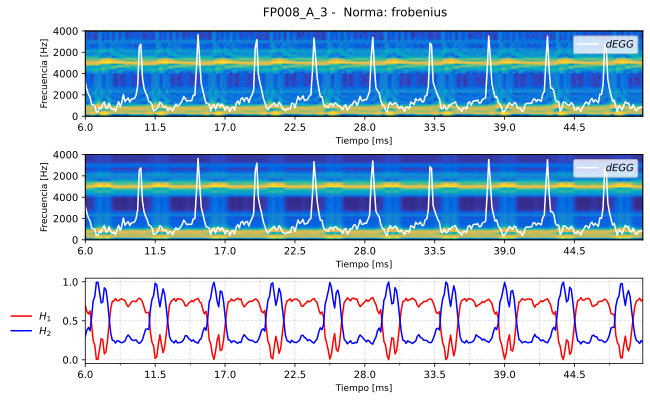

In [4]:
fig,ax = plt.subplots(3,1,figsize=(10,6))
plt.subplots_adjust(hspace=0.45)
ax1 = ax[0]
ax1_ = ax1.twinx()
ax2 = ax[1]
ax2_ = ax2.twinx()
ax3 = ax[2]
''' 
ax7 = fig.add_subplot(gs[3,0:2])
ax7_ = ax7.twinx()
ax8 = fig.add_subplot(gs[3,2:])
ax8_ = ax8.twinx()
ax9 = fig.add_subplot(gs[4,0:2])
ax9_ = ax9.twinx()
ax10 = fig.add_subplot(gs[4,2:])
ax10_ = ax10.twinx()
''' 

#axes = [ax1,ax1_,ax2,ax3, ax4,ax5,ax6,ax7,ax7_,ax8,ax8_,ax9,ax9_,ax10,ax10_]
fontsize = 9

#========================= Espectrograma aproximado sincronizado
ax1.imshow(SP.espectrograma_plot_original,
                cmap=cmap,
                origin='lower',
                aspect='auto',
                extent=[SP.to_espectrograma_sincronizado, SP.tf_espectrograma_sincronizado,
                        SP.fo_espectrograma, 2*SP.ff_espectrograma])
ax1.set_ylabel('Frecuencia [Hz]',fontsize=fontsize)
yticks = [0, 2000, 4000, 6000, 8000]
ax1.set_yticks(yticks)
ax1.set_yticklabels(['0', '2000', '4000', '2000', '4000'])
#ax1.set_xlabel("Tiempo [ms]")

# ------------- dEGG
ax1_.tick_params(labelbottom=False)
ax1_.plot(SP.tiempos_espectrograma_sincronizado,SP.dEGG_sincronizado,color='white', label=r"$dEGG$", linewidth=line_width)
ax1_.legend(loc=legend_loc)
ax1_.set_xlim(SP.to_espectrograma_sincronizado, SP.tf_espectrograma_sincronizado)
ax1_.set_xticks(np.arange(SP.to_espectrograma_sincronizado, SP.tf_espectrograma_sincronizado, SP.duracion_ventana))
ax1_.set_yticks([])
ax1.set_xlabel('Tiempo [ms]',fontsize=fontsize)
#========================= Espectrograma aproximado sincronizado
ax2.imshow(SP.espectrograma_aprox_plot,
                cmap=cmap,
                origin='lower',
                aspect='auto',
                extent=[SP.to_espectrograma_sincronizado, SP.tf_espectrograma_sincronizado,
                        SP.fo_espectrograma, 2*SP.ff_espectrograma])
ax2.set_ylabel('Frecuencia [Hz]',fontsize=fontsize)
yticks = [0, 2000, 4000, 6000, 8000]
ax2.set_yticklabels(['0', '2000', '4000', '2000', '4000'])
ax2.set_yticks(yticks)
#ax1.set_xlabel("Tiempo [ms]")
ax2.set_xlabel('Tiempo [ms]',fontsize=fontsize)
# ------------- dEGG
ax2_.tick_params(labelbottom=False)
ax2_.plot(SP.tiempos_espectrograma_sincronizado,SP.dEGG_sincronizado,color='white', label=r"$dEGG$", linewidth=line_width)
ax2_.legend(loc=legend_loc)
ax2_.set_xlim(SP.to_espectrograma_sincronizado, SP.tf_espectrograma_sincronizado)
ax2_.set_xticks(np.arange(SP.to_espectrograma_sincronizado, SP.tf_espectrograma_sincronizado, SP.duracion_ventana))
ax2_.set_yticks([])
#========================= Funciones de activación
ax3.plot(SP.tiempos_espectrograma_sincronizado,SP.H1,color=color1)
ax3.plot(SP.tiempos_espectrograma_sincronizado,SP.H2,color=color2)
ax3.set_xlim(SP.to_espectrograma_sincronizado,SP.tf_espectrograma_sincronizado)
ax3.set_xticks(np.arange(SP.to_espectrograma_sincronizado,SP.tf_espectrograma_sincronizado,SP.duracion_ventana))
ax3.set_xticks(np.arange(SP.to_espectrograma_sincronizado,SP.tf_espectrograma_sincronizado,SP.duracion_ventana/2),minor=True)
ax3.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
#ax2.legend(loc=legend_loc)
ax3.set_xlabel('Tiempo [ms]',fontsize=fontsize)

handles = [
    plt.Line2D([0], [0], color=color1,  label=r'$H_1$'),
    plt.Line2D([0], [0], color=color2,  label=r'$H_2$'),
]
titulo = nombre_archivo.split(".txt")[0] + " -  Norma: " + norma 

fig.suptitle(titulo,
             fontsize=12,
             x=0.50,y=0.935)

fig.legend(handles=handles,
           loc='upper center',
           bbox_to_anchor=(0.05, 0.25),  # ← misma altura, más a la derecha
           frameon=False);
fig.savefig("CO-NMF_espectrograma_"+nombre_archivo+".pdf",bbox_inches = 'tight');


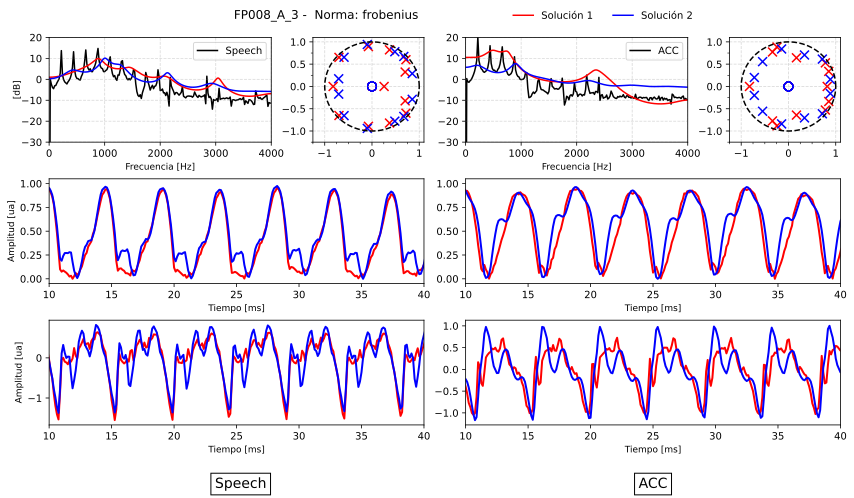

In [ ]:
fig = plt.figure(figsize=(11,7))
widths  = [1,0.5,1,0.5]
heights = [1,1,1]
gs  = fig.add_gridspec(3, 4,width_ratios=widths,height_ratios=heights,left=0,right=1,wspace=0.25,hspace=0.35)

# Señales temporales
ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1])
ax3 = fig.add_subplot(gs[0,2])
ax4 = fig.add_subplot(gs[0,3])

ax5 = fig.add_subplot(gs[1,0:2])
ax6 = fig.add_subplot(gs[1,2:])

ax7 = fig.add_subplot(gs[2,0:2])
ax8 = fig.add_subplot(gs[2,2:])

axes = [ax1,ax1,ax2,ax3,ax4,ax5,ax6,ax7,ax8]
fontsize = 9
line_width = 2

#========================= Respuesta en frecuencia/polos-ceros speech
# ------------- Respuesta en frecuencia
theta = np.linspace(0, 2*np.pi, 200)
fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
fw1,hw1 = sig.freqz([1],SP.a_W1_speech,fs=fs_r)
fw2,hw2 = sig.freqz([1],SP.a_W2_speech,fs=fs_r)
ax1.plot(fw1, 10*np.log10(np.abs(hw1)), color=color1)
ax1.plot(fw2, 10*np.log10(np.abs(hw2)), color=color2)
ax1.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='Speech', color=color3, zorder=-1)
ax1.set_xlim(0,fs_r/2)
ax1.grid(True, linestyle='dashed', color='gray', alpha=0.3)
ax1.set_xlabel('Frecuencia [Hz]',fontsize=fontsize)
ax1.set_ylabel('[dB]',labelpad=-0.5,fontsize=fontsize)
ax1.set_ylim([-30,20])
ax1.legend(loc='upper right')
# ------------- Polos y ceros   
ax2.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
#ax4.yaxis.tick_right()
#ax4.yaxis.set_label_position("right")
ax2.scatter(np.real(SP.ceros_W1_speech), np.imag(SP.ceros_W1_speech),s=80, facecolors='none', edgecolors=color1, label='Ceros')
ax2.scatter(np.real(SP.polos_W1_speech), np.imag(SP.polos_W1_speech),s=80, marker='x', color=color1, label='Polos')
ax2.scatter(np.real(SP.ceros_W2_speech), np.imag(SP.ceros_W2_speech),s=80, facecolors='none', edgecolors=color2, label='Ceros')
ax2.scatter(np.real(SP.polos_W2_speech), np.imag(SP.polos_W2_speech),s=80, marker='x', color=color2, label='Polos')
ax2.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
ax2.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
#ax4.set_ylabel(r"$Im\{z\}$",labelpad=-0.5)
#ax4.set_xlabel(r"$Re\{z\}$")
ax2.grid(True, linestyle='dashed', color='gray', alpha=0.3)
#========================= Respuesta en frecuencia/polos-ceros ACC
# ------------- Respuesta en frecuencia
fftseñal, fseñal = Funciones.FFT(señal_ACC, fs_r)
fw1,hw1 = sig.freqz([1],SP.a_W1_acc,fs=fs_r)
fw2,hw2 = sig.freqz([1],SP.a_W2_acc,fs=fs_r)
ax3.plot(fw1, 10*np.log10(np.abs(hw1)), color=color1)
ax3.plot(fw2, 10*np.log10(np.abs(hw2)), color=color2)
ax3.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='ACC', color=color3, zorder=-1)
ax3.set_xlim(0,fs_r/2)
ax3.grid(True, linestyle='dashed', color='gray', alpha=0.3)
ax3.set_xlabel('Frecuencia [Hz]',fontsize=fontsize)
#ax5.set_ylabel('[dB]',labelpad=-0.5)
ax3.set_ylim([-30,20])
ax3.legend(loc='upper right')
# ------------- Polos y ceros   
ax4.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
#ax6.yaxis.tick_right()
#ax6.yaxis.set_label_position("right")
ax4.scatter(np.real(SP.ceros_W1_acc), np.imag(SP.ceros_W1_acc),s=80, facecolors='none', edgecolors=color1, label='Ceros')
ax4.scatter(np.real(SP.polos_W1_acc), np.imag(SP.polos_W1_acc),s=80, marker='x', color=color1, label='Polos')
ax4.scatter(np.real(SP.ceros_W2_acc), np.imag(SP.ceros_W2_acc),s=80, facecolors='none', edgecolors=color2, label='Ceros')
ax4.scatter(np.real(SP.polos_W2_acc), np.imag(SP.polos_W2_acc),s=80, marker='x', color=color2, label='Polos')
ax4.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
ax4.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
#ax6.set_ylabel(r"$Im\{z\}$",labelpad=-0.5)
#ax6.set_xlabel(r"$Re\{z\}$")
ax4.grid(True, linestyle='dashed', color='gray', alpha=0.3)
#ax6.legend(loc='upper right')

#========================= Flujos speech
to_ =10
tf_ = 40
#ax5.plot(tiempos,flujo_ovv,color='k',alpha=0.7);
ax5.plot(SP.tiempos_gve,Funciones.Sincronizar(conmf_flujo1_speech,flujo_ovv),color=color1, linewidth=line_width)
ax5.plot(SP.tiempos_gve,Funciones.Sincronizar(conmf_flujo2_speech,flujo_ovv),color=color2, linewidth=line_width)

ax5.set_xlim([to_,tf_])
ax5.set_xlabel('Tiempo [ms]',fontsize=fontsize)
#ax5.set_title('Speech',fontsize=13)
ax5.set_ylabel("Amplitud [ua]",fontsize=fontsize)
#========================= Flujos ACC
#ax6.plot(tiempos,flujo_ovv,color='k',alpha=0.7);
ax6.plot(SP.tiempos_gve,Funciones.Sincronizar(conmf_flujo1_acc,flujo_ovv),color=color1, linewidth=line_width)
ax6.plot(SP.tiempos_gve,Funciones.Sincronizar(conmf_flujo2_acc,flujo_ovv),color=color2, linewidth=line_width)
ax6.set_xlim([to_,tf_])
#ax6.set_xticks(np.arange(to,tf,2.5),minor=True)
ax6.set_xlabel('Tiempo [ms]',fontsize=fontsize)  
#========================= Funciones glóticas speech
#ax7.plot(tiempos,np.gradient(flujo_ovv,tiempos),color='k',alpha=0.7);
ax7.plot(SP.tiempos_gve,np.gradient(conmf_flujo1_speech,tiempos),color=color1, linewidth=line_width)
ax7.plot(SP.tiempos_gve,np.gradient(conmf_flujo2_speech,tiempos),color=color2, linewidth=line_width)
ax7.set_xlim([to_,tf_])
ax7.set_xlabel('Tiempo [ms]',fontsize=fontsize)
ax7.set_ylabel("Amplitud [ua]",fontsize=fontsize)
plt.text(-0.6, -0.5, "Speech",fontsize=14,
         ha='center', va='top',
         transform=plt.gca().transAxes,
         bbox=dict(facecolor='white', edgecolor='black'))

#========================= Funciones glóticas ACC
ax8.plot(SP.tiempos_gve,np.gradient(conmf_flujo1_acc,tiempos),color=color1, linewidth=line_width)
ax8.plot(SP.tiempos_gve,np.gradient(conmf_flujo2_acc,tiempos),color=color2, linewidth=line_width)
ax8.set_xlim([to_,tf_])
ax8.set_xlabel('Tiempo [ms]',fontsize=fontsize);

handles = [
    plt.Line2D([0], [0], color=color1, label='Solución 1'),
    plt.Line2D([0], [0], color=color2, label='Solución 2'),
]
titulo = nombre_archivo.split(".txt")[0] + " -  Norma: " + norma 

fig.suptitle(titulo,
             fontsize=12,
             x=0.35,y=0.935)

fig.legend(handles=handles,
           loc='upper center',
           bbox_to_anchor=(0.7, 0.95),  # ← misma altura, más a la derecha
           ncol=3,
           frameon=False);
plt.text(0.5, -0.5, "ACC",fontsize=14,
         ha='center', va='top',
         transform=plt.gca().transAxes,
         bbox=dict(facecolor='white', edgecolor='black'))
fig.savefig("CO-NMF_solucion_"+nombre_archivo+".pdf",bbox_inches = 'tight');